<a href="https://colab.research.google.com/github/apenkals/Spatial_Programming_2026/blob/main/PracticeOpenSource.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
DATA_BASE = "https://raw.githubusercontent.com/pjbitterman/KSU_x9076/main/data"

In [3]:
import geopandas as gpd
# doing this means you can just import gpd instead of typing out geopands each time

streams = gpd.read_file(f"{DATA_BASE}/part1/streams_portage.geojson")
streams.head()
# hover over streams.head() and it will show the sizes and type (geodataframe)
# shows the contents of the file
# reaching the file in patricks cloud repo, f string...
# geopandas are just like a big table and on the right side is the geometry

,osm_id,name,waterway,geometry
0,1133257290,None,stream,"LINESTRING (-81.19577 40.9884, -81.19562 40.98..."
1,1133257293,None,stream,"LINESTRING (-81.20048 40.99369, -81.20035 40.9..."
2,1133257292,None,stream,"LINESTRING (-81.1958 40.99254, -81.19644 40.99..."
3,1133257294,None,stream,"LINESTRING (-81.2005 40.9938, -81.20048 40.99369)"
4,1133257296,None,stream,"LINESTRING (-81.20098 40.99481, -81.20075 40.9..."


In [5]:
type(streams)
# details about files

geopandas.geodataframe.GeoDataFrame

In [7]:
streams["waterway"] # one column, by name -> a series (a single labeled column)
streams["waterway"].value_counts() # methods chain onto that column
# streams.columns lists the names; equivalent to arcpy.ListFields
streams.columns

Index(['osm_id', 'name', 'waterway', 'geometry'], dtype='object')

In [8]:
# One set of brackets returns one column; two sets of brackets return several columns, still
# as a table. streams[["name", "waterway"]] (inner brackets are a list of names, outer brackets
# do the selecting).
# A condition inside of brackets filters rows, NOT columns.
#     streams[streams["name"].notna()] keeps only the rows where name has a value.

In [10]:
print(f"{len(streams)} stream segments")
print(streams.crs)
streams["waterway"].value_counts()
#

1989 stream segments
EPSG:4326


,count
waterway,
stream,1778
ditch,173
river,27
canal,11


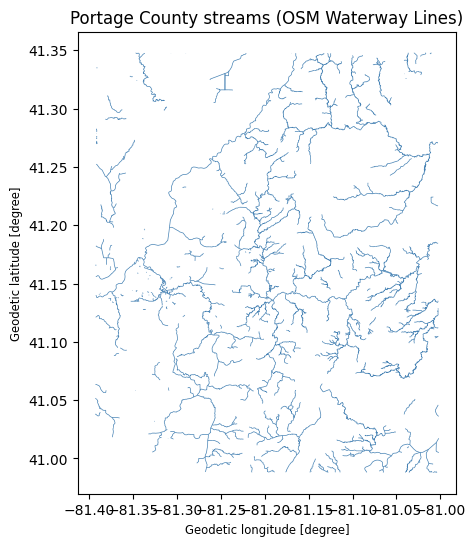

In [16]:
import matplotlib.pyplot as plt
# we just want pyplot which is part of matplotlib
fig, ax = plt.subplots(figsize=(6,6))

streams.plot(ax=ax, linewidth=0.5, color="steelblue")

ax.set_title("Portage County streams (OSM Waterway Lines)")

plt.show()

In [17]:
named = streams[streams["name"].notna()]
                # notna tosses out every row that hases na; so if its missing
                # a name it will discard it.
print(f"{len(named)} of {len(streams)} segments have a name")
named[["name", "waterway"]].head()

247 of 1989 segments have a name


,name,waterway
19,Deer Creek,stream
20,Deer Creek,stream
21,Deer Creek,stream
24,Deer Creek,stream
144,Deer Creek,stream


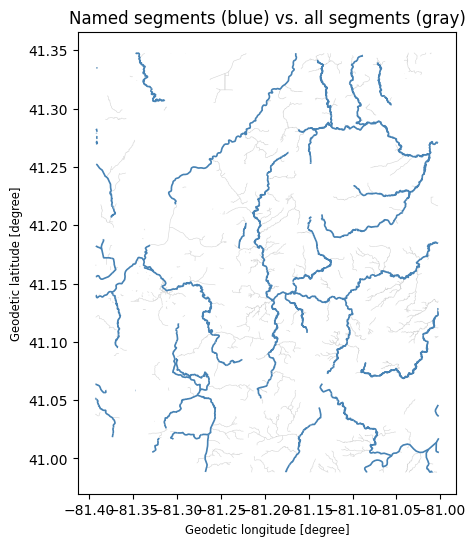

In [18]:
fig, ax = plt.subplots(figsize=(6, 6))
streams.plot(ax=ax, linewidth=0.4, color="lightgray")
named.plot(ax=ax, linewidth=1.2, color="steelblue")
ax.set_title("Named segments (blue) vs. all segments (gray)")
plt.show()
# can plot things on the same axis
# segments are grey with blue that just have names
# goes in order; called streams first, then name. so put grey before blue.